# 06 — Frozen-model validation and engineering assessment
**MMA3001 · Machine Failure Prediction · AI4I 2020**

## 1. Evaluation objective and frozen configuration

This notebook reconstructs the previously selected Decision Tree with `max_depth=9`, `min_samples_leaf=10`, `random_state=42` and decision threshold **0.50**, trains it using the same **8,000 development observations**, and reports its performance on the **2,000-row previously inspected held-out subset**. No model search or threshold optimisation takes place here. Fixed comparators are Logistic Regression (`C=1`, threshold `0.20`) and an all-normal majority classifier.

**Validation provenance.** The original development history included test inspections for earlier candidates and this selected tree (archived in Notebook 05). Reconstructing the fixed evaluation does **not** produce an untouched independent test set. These results therefore support a within-dataset comparison, but their generalisation claims are limited.

**Prediction scope.** The six operating inputs classify a **synthetic machine-failure label associated with the recorded operating conditions**. The dataset does not define a validated future prediction horizon, time to failure or remaining useful life, and the trained model has not been field-deployed.

This notebook is self-contained. Place it in `notebooks/` with the original CSV at `data/raw/ai4i2020.csv`. Any saved outputs document earlier execution; re-execute in the intended environment to reproduce them.

## 2. Imports, dataset loading and split

Reproduce the original 80/20 stratified split with seed 42 and unchanged row order. Use only
the six specified predictors. `UDI`, `Product ID`, `TWF`, `HDF`, `PWF`, `OSF` and `RNF` are
excluded; failure-mode labels are inappropriate ordinary inputs because they risk target
leakage. Assertions check the expected dataset and split counts rather than generating data.

In [22]:
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from pathlib import Path
from sklearn.model_selection import train_test_split

# Exact data schema used throughout the original experiments.
RANDOM_STATE = 42
TARGET = "Machine failure"
CATEGORICAL_FEATURES = ["Type"]
NUMERIC_FEATURES = [
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]",
]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

# Accept execution from the repository root or its notebooks/ directory.
# No extra .py helper file is needed.
DATA_PATH = Path("data/raw/ai4i2020.csv")
if not DATA_PATH.is_file():
    DATA_PATH = Path("../data/raw/ai4i2020.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Cannot locate data/raw/ai4i2020.csv. Open the project root "
        "or its notebooks/ folder in VS Code and keep the original CSV in data/raw/. "
        f"Current working directory: {Path.cwd()}"
    )

df = pd.read_csv(DATA_PATH)

# These six inputs are available at prediction time; failure-mode flags and IDs
# are deliberately excluded because they could leak the target or identify rows.
required_columns = FEATURES + [TARGET]
missing_columns = [name for name in required_columns if name not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")
if df[required_columns].isna().any().any():
    raise ValueError("Missing values found in the selected modelling columns.")

X = df[FEATURES].copy()
y = df[TARGET].copy()

# Use precisely the same stratified, seeded 80/20 row split in every notebook.
# Stratification maintains approximately 3.39% failures in each subset.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y,
)

# Assertions check identical source rows and split; they do not alter either.
assert len(df) == 10000 and set(df[TARGET].unique()) == {0, 1} and int(df[TARGET].sum()) == 339, \
    "The dataset does not match the original AI4I basis."
assert (len(X_train), int(y_train.sum())) == (8000, 271)
assert (len(X_test), int(y_test.sum())) == (2000, 68)
display(pd.DataFrame({
    "Observations": [len(X_train), len(X_test)],
    "Failures": [int(y_train.sum()), int(y_test.sum())],
}, index=["Development", "Previously inspected held-out test"]))

,Observations,Failures
Development,8000,271
Previously inspected held-out test,2000,68


## 3. Reconstruct the frozen modelling pipeline

The five numerical measurements pass directly to the Decision Tree; categorical `Type` uses `OneHotEncoder(drop="first", handle_unknown="ignore")`, reproducing the original feature transformation. The binary prediction follows the fixed `probability >= 0.50` rule. Ranking quality is reported as ROC-AUC and scikit-learn average precision (“PR-AUC”).

In [23]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            NUMERIC_FEATURES,
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
            ),
            CATEGORICAL_FEATURES,
        ),
    ]
)



FINAL_TREE_DEPTH = 9
FINAL_TREE_MIN_LEAF = 10
FINAL_TREE_THRESHOLD = 0.50

final_tree_model = Pipeline([
    ("preprocessing", tree_preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=FINAL_TREE_DEPTH,
        min_samples_leaf=FINAL_TREE_MIN_LEAF,
        random_state=RANDOM_STATE,
    )),
])

### Metric definitions shared by the three fixed comparators

`evaluate_threshold()` applies the specified alarm cut-off and returns confusion-matrix counts, accuracy, balanced accuracy, precision, recall and F1. `evaluate_probabilities()` adds ROC-AUC and average precision. Reusing these two **local notebook functions** applies the same definitions to the tree, Logistic Regression and majority baseline; no external helper or package is required.

In [24]:
def evaluate_threshold(
    y_true,
    probabilities,
    threshold,
):
    """
    Evaluate binary classification performance at a
    specified probability threshold.

    Parameters
    ----------
    y_true : array-like
        Ground-truth binary target values.
    probabilities : array-like
        Predicted probabilities for machine failure.
    threshold : float
        Probability threshold used to classify failure.

    Returns
    -------
    dict
        Classification metrics and confusion-matrix counts.
    """

    y_pred = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "Balanced Accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred,
            ),
        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "F1-score": f1_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "True Negatives": tn,
    }



def evaluate_probabilities(y_true, probabilities, threshold):
    """Return the original classification metrics plus ranking metrics."""
    metrics = evaluate_threshold(y_true, probabilities, threshold)
    metrics["ROC-AUC"] = roc_auc_score(y_true, probabilities)
    metrics["PR-AUC"] = average_precision_score(y_true, probabilities)
    return metrics

## 4. Selected Decision Tree: previously inspected held-out results

Only the development observations are used for fitting. The test subset is then used to calculate model scores and a labelled confusion matrix (actual classes as rows, predicted classes as columns). These are **reproduced held-out-subset metrics from an already-inspected split**, not a fresh independent experiment.

In [25]:
final_tree_model.fit(X_train, y_train)
final_tree_test_probability = final_tree_model.predict_proba(X_test)[:, 1]
final_tree_test_prediction = (
    final_tree_test_probability >= FINAL_TREE_THRESHOLD
).astype(int)
final_tree_test_metrics = evaluate_probabilities(
    y_test, final_tree_test_probability, FINAL_TREE_THRESHOLD,
)
final_test_results = pd.DataFrame(
    [final_tree_test_metrics], index=["Frozen Decision Tree"],
)
final_test_results.insert(0, "Evaluation basis", "Held-out test (previously inspected)")
display(final_test_results.round(4))

,Evaluation basis,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives,ROC-AUC,PR-AUC
Frozen Decision Tree,Held-out test (previously inspected),0.5,0.9825,0.8207,0.8,0.6471,0.7154,11,24,44,1921,0.8961,0.7601


,Predicted normal (0),Predicted failure (1)
Actual normal (0),1921,11
Actual failure (1),24,44


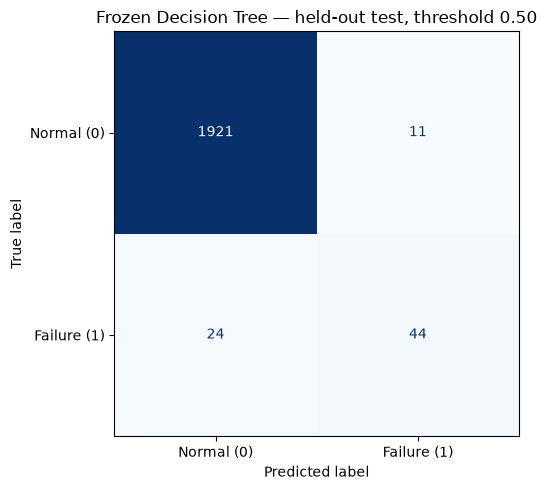

In [26]:
final_cm = confusion_matrix(y_test, final_tree_test_prediction, labels=[0, 1])
display(pd.DataFrame(
    final_cm,
    index=["Actual normal (0)", "Actual failure (1)"],
    columns=["Predicted normal (0)", "Predicted failure (1)"],
))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=final_cm, display_labels=["Normal (0)", "Failure (1)"],
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Frozen Decision Tree — held-out test, threshold 0.50")
fig.tight_layout()
plt.show()

## 5. Fixed baseline comparison on the same observations

All three models use the same previously inspected 2,000-row subset. The majority model always predicts the development majority class; its constant failure scores provide a no-skill ranking reference. Logistic Regression retains the original unweighted `C=1`, scaled numerical variables, matching `Type` encoding, `max_iter=1000`, seed 42 and threshold **0.20**. The final Decision Tree remains fixed at threshold **0.50**. These are **different preselected operating thresholds**; the table compares the recorded alarm policies as well as their ranking scores.

No Linear Regression test results are invented here because Notebook 03 only establishes development OOF evidence.

In [29]:
LOGISTIC_THRESHOLD = 0.20
logistic_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC_FEATURES),
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"),
     CATEGORICAL_FEATURES),
])
logistic_benchmark = Pipeline([
    ("preprocessing", logistic_preprocessor),
    ("model", LogisticRegression(C=1, max_iter=1000, random_state=RANDOM_STATE)),
])
logistic_benchmark.fit(X_train, y_train)
logistic_test_probability = logistic_benchmark.predict_proba(X_test)[:, 1]

# DummyClassifier ignores feature values; only the development labels determine its class.
majority_benchmark = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
majority_benchmark.fit(X_train, y_train)
failure_column = list(majority_benchmark.classes_).index(1)
majority_test_probability = majority_benchmark.predict_proba(X_test)[:, failure_column]

test_comparison = pd.DataFrame([
    evaluate_probabilities(y_test, majority_test_probability, 0.50),
    evaluate_probabilities(y_test, logistic_test_probability, LOGISTIC_THRESHOLD),
    final_tree_test_metrics,
], index=["Majority class", "Logistic Regression (C=1)", "Frozen Decision Tree"])
test_comparison.insert(0, "Evaluation basis", "Held-out test (previously inspected)")
display(test_comparison.round(4))

,Evaluation basis,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives,ROC-AUC,PR-AUC
Majority class,Held-out test (previously inspected),0.5,0.9660,0.5000,0.0000,0.0000,0.0000,0,68,0,1932,0.5000,0.0340
Logistic Regression (C=1),Held-out test (previously inspected),0.2,0.9620,0.7249,0.4444,0.4706,0.4571,40,36,32,1892,0.8995,0.4215
Frozen Decision Tree,Held-out test (previously inspected),0.5,0.9825,0.8207,0.8000,0.6471,0.7154,11,24,44,1921,0.8961,0.7601


### Development evidence is not the same as test evidence

The selected-tree pooled development OOF metrics from Notebook 05 appear below as a saved reference, not a new cross-validation run. The displayed test-minus-development differences describe these two evaluation samples; they are **not uncertainty intervals or statistical significance tests**. The mean PR-AUC across repeated folds (0.6921) is not the same calculation as pooled development OOF PR-AUC (0.7050).

In [28]:
development_oof_reference = pd.Series({
    "Accuracy": 0.9825, "Balanced Accuracy": 0.8254,
    "Precision": 0.7911, "Recall": 0.6568, "F1-score": 0.7177,
    "ROC-AUC": 0.9179, "PR-AUC": 0.7050,
}, name="Saved development pooled OOF (rounded)")
display(development_oof_reference.to_frame())
held_out_scores = pd.Series(final_tree_test_metrics).reindex(development_oof_reference.index)
display((held_out_scores - development_oof_reference).rename(
    "Held-out test minus saved development OOF (approximate)"
).to_frame().round(4))

,Saved development pooled OOF (rounded)
Accuracy,0.9825
Balanced Accuracy,0.8254
Precision,0.7911
Recall,0.6568
F1-score,0.7177
ROC-AUC,0.9179
PR-AUC,0.7050


,Held-out test minus saved development OOF (approximate)
Accuracy,0.0000
Balanced Accuracy,-0.0047
Precision,0.0089
Recall,-0.0097
F1-score,-0.0023
ROC-AUC,-0.0218
PR-AUC,0.0551


## Final Results and Engineering Limitations

The final Decision Tree was evaluated on 2,000 observations containing 68 machine failures.

It correctly detected 44 failures, missed 24 and produced 11 false alarms. This gave precision = 0.8000, recall = 0.6471, F1-score = 0.7154 and PR-AUC = 0.7601.

Compared with Logistic Regression, the Decision Tree detected 12 more failures while producing 29 fewer false alarms. However, Logistic Regression achieved a slightly higher ROC-AUC.

The Decision Tree therefore performed better on the main failure-detection measures, although it still missed approximately 35% of failures.

### Limitations

- **Synthetic data:** Results may not represent performance on actual industrial machines.
- **No failure timing:** The model identifies failure-labelled conditions but cannot predict when a breakdown will occur.
- **Test-set inspection:** Earlier experiments examined the test data, reducing the independence of the final evaluation.
- **Limited generalisation evidence:** Performance on different machines, factories or future operating data remains unknown.

**Conclusion:** The Decision Tree outperformed the tested alternatives on the main failure-detection measures. However, its missed failures and validation limitations mean further real-world testing is required before industrial deployment.